In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf
from sklearn.metrics import mean_squared_error
from statsmodels.tsa.statespace.sarimax import SARIMAX

# 1. Load data
df = pd.read_csv("C:\\Users\\kekko\\Downloads\\student_dataset.csv")
df['time'] = pd.to_datetime(df['time'])

# 2. CRITICAL: Set the index and frequency
# This solves the "ValueWarning: An unsupported index" error
df = df.set_index('time')
df = df.asfreq('h') # Tells statsmodels: "This is hourly data"



In [2]:
# 3. Create Exogenous Features
# This allows the model to learn that Saturday != Sunday
df['is_saturday'] = (df.index.dayofweek == 5).astype(int)
df['is_sunday'] = (df.index.dayofweek == 6).astype(int)

# B. Smart Holiday Detection
daily_sum = df['value'].resample('D').sum()
# Identify the quietest 10% of days (likely holidays)
holiday_threshold = daily_sum.quantile(0.10) 
low_activity_days = daily_sum[daily_sum < holiday_threshold].index

# Map to hourly
df['is_low_day'] = df.index.normalize().isin(low_activity_days).astype(int)

# C. CREATE "WEEKDAY VACATION" (The Secret Weapon)
# This flag is 1 ONLY if it's a holiday AND it falls on a Mon-Fri.
# This prevents it from fighting with the Saturday/Sunday flags.
df['is_weekday_vacation'] = (
    (df['is_low_day'] == 1) & 
    (df['is_saturday'] == 0) & 
    (df['is_sunday'] == 0)
).astype(int)

In [3]:
# 3. Split Data
train = df[df['value'].notnull()].tail(4000) 
y_log = np.log1p(train['value'])

# Select ONLY the non-overlapping features
# We dropped 'is_august' because data shows it's not actually a 'low' month in your set
exog_features = ['is_saturday', 'is_sunday', 'is_weekday_vacation']
exog_train = train[exog_features]

In [4]:
# 5. Define Model
# Note: Since we set the freq in step 2, forecasting will now work.
model = SARIMAX(y_log, 
                exog=exog_train,
                order=(2, 1, 1), 
                seasonal_order=(1, 1, 1, 24),
                enforce_stationarity=False,
                enforce_invertibility=False)

# 5. FIT with Higher Iterations (Fixes Convergence Warning)
# We use method='powell' or increase maxiter to ensure it finds the solution
results = model.fit(disp=False, maxiter=500)

In [5]:
# 6. FORECAST
to_forecast = df[df['value'].isnull()]
exog_forecast = to_forecast[exog_features]

forecast_res = results.get_forecast(steps=len(to_forecast), exog=exog_forecast)
forecast_final = np.expm1(forecast_res.predicted_mean)

In [6]:
# 7. Fill the NAs back in the original dataframe
df.loc[df['value'].isnull(), 'value'] = forecast_final

# Reset index if you want the 'time' column back as a normal column
df = df.reset_index()
print(df.tail())

                     time     value  is_saturday  is_sunday  is_low_day  \
42762 2020-02-29 18:00:01  3.484715            1          0           1   
42763 2020-02-29 19:00:01  2.099435            1          0           1   
42764 2020-02-29 20:00:01  1.580587            1          0           1   
42765 2020-02-29 21:00:01  0.761050            1          0           1   
42766 2020-02-29 22:00:01  0.060648            1          0           1   

       is_weekday_vacation  
42762                    0  
42763                    0  
42764                    0  
42765                    0  
42766                    0  


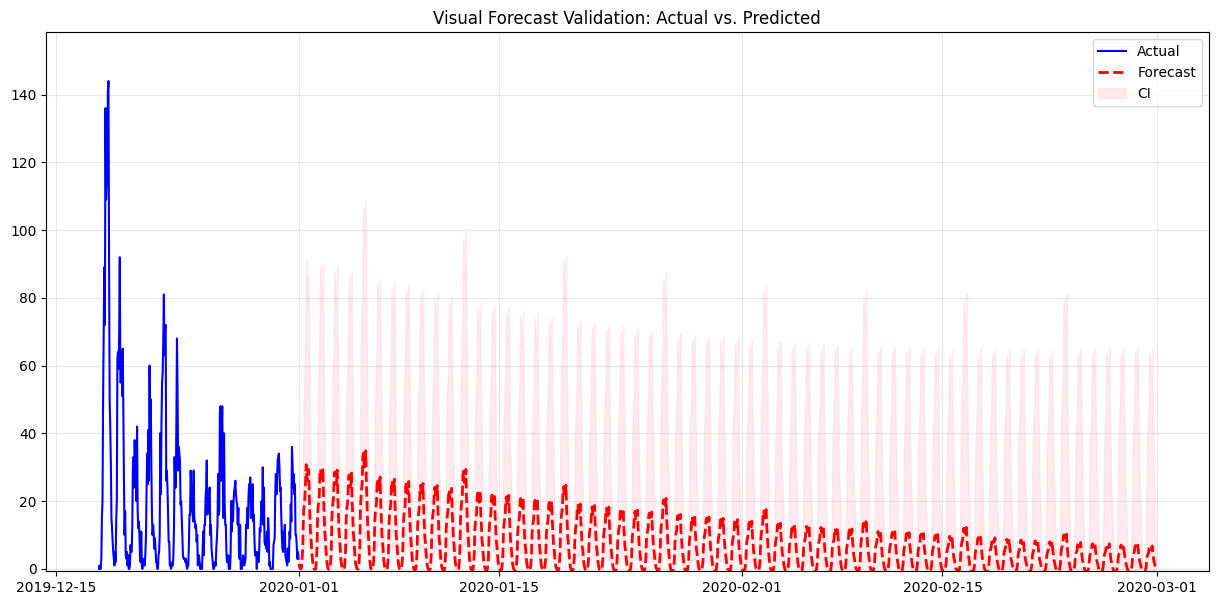

In [7]:
# 8. Visual Validation
plt.figure(figsize=(15, 7))

# Plot actual data (last 14 days)
plt.plot(train.index[-336:], np.expm1(y_log.tail(336)), label='Actual', 
         color='b', lw=1.5)

# Plot forecast & confidence intervals
plt.plot(to_forecast.index, forecast_final, label='Forecast', 
         color='r', ls='--', lw=2)
plt.fill_between(to_forecast.index, *np.expm1(forecast_res.conf_int()).values.T, 
                 color='pink', alpha=0.3, label='CI')

# Dynamic Y-axis limits
all_vals = np.concatenate([np.expm1(y_log.tail(336)), forecast_final])
plt.ylim(all_vals.min() * 0.9, all_vals.max() * 1.1)

plt.title("Visual Forecast Validation: Actual vs. Predicted")
plt.legend(); plt.grid(True, alpha=0.3); plt.show()

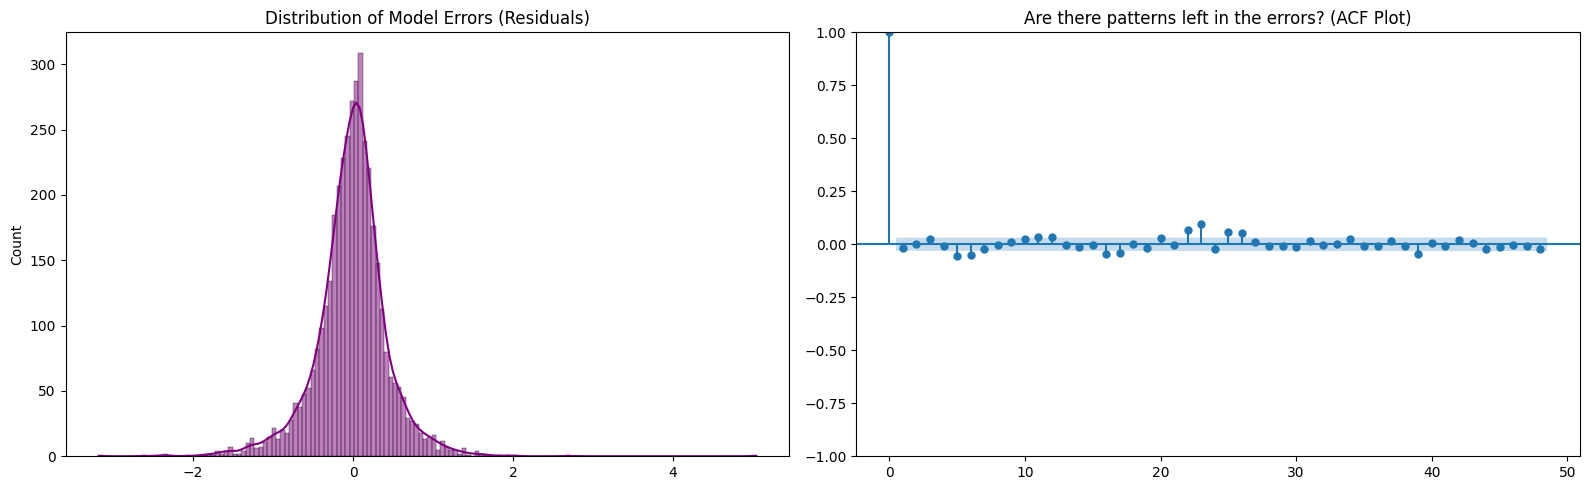

In [8]:
# 2. STATISTICAL CHECK: Residual Analysis
# "Residuals" are the errors. We want them to look like random noise.
residuals = results.resid

fig, ax = plt.subplots(1, 2, figsize=(16, 5))

# Plot 1: Distribution of Errors (Should be a Bell Curve/Normal)
sns.histplot(residuals, kde=True, ax=ax[0], color='purple')
ax[0].set_title('Distribution of Model Errors (Residuals)')

# Plot 2: ACF of Residuals (Should have no significant spikes)
# If spikes exist, it means there is still a pattern the model didn't catch.
plot_acf(residuals, lags=48, ax=ax[1])
ax[1].set_title('Are there patterns left in the errors? (ACF Plot)')

plt.tight_layout()
plt.show()

In [9]:
# 3. PRINT MODEL METRICS and PARAMETERS and MSE and RMSE
mse = mean_squared_error(y_log, results.fittedvalues)
rmse = np.sqrt(mse)


print("--- Model Statistics ---")
print(f"MSE: {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"AIC: {results.aic:.2f}") # Lower is better
print(f"BIC: {results.bic:.2f}")
print("\nTop Parameters:")
print(results.params.sort_values(ascending=False).head(5))

--- Model Statistics ---
MSE: 0.2013
RMSE: 0.4487
AIC: 4594.49
BIC: 4651.02

Top Parameters:
ar.L1        0.474393
sigma2       0.183192
ar.L2        0.177332
ar.S.L24     0.122614
is_sunday    0.025392
dtype: float64


--- Optimized Model Results ---
AIC: 4594.49

Coefficients (We expect all to be negative):
is_saturday           -0.201288
is_sunday              0.025392
is_weekday_vacation   -0.194618
dtype: float64


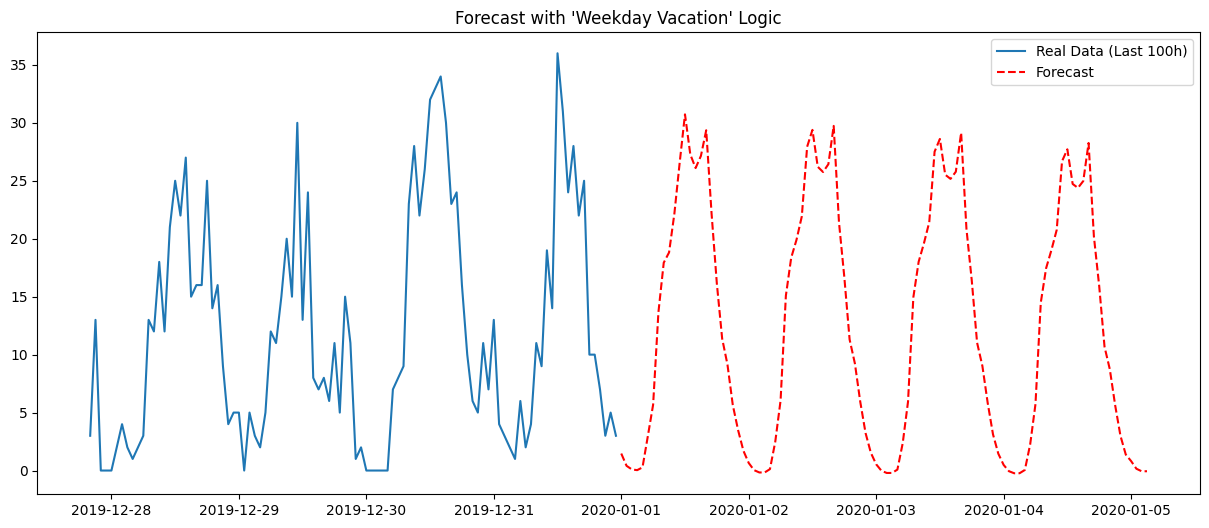

In [10]:
# 7. EXPORT & STATS
df.loc[df['value'].isnull(), 'value'] = forecast_final
df.loc[df['value'] < 0, 'value'] = 0

print("--- Optimized Model Results ---")
print(f"AIC: {results.aic:.2f}") 
print("\nCoefficients (We expect all to be negative):")
print(results.params[exog_features])

# Plotting the impact
plt.figure(figsize=(15, 6))
plt.plot(train.index[-100:], train['value'][-100:], label='Real Data (Last 100h)')
plt.plot(to_forecast.index[:100], forecast_final[:100], label='Forecast', color='red', linestyle='--')
plt.title("Forecast with 'Weekday Vacation' Logic")
plt.legend()
plt.show()